# Transaction-monitoring agent with memory

Banks check every card payment for fraud. Analysis takes place on an individual transaction as well as matching historical usage patterns. In this workshop you'll build an agent that does the same job:

- It processes a **stream of transactions** for each customer, one at a time, and looks each one up in the
  bank's database.
- **Short-term memory** lets it remember earlier transactions in the same stream.
- **Long-term memory** lets it remember facts about a customer across conversations, such as "on holiday in
  Portugal".
- It gives every transaction a **risk score** and a **confidence**. When its confidence is low, it pauses and
  asks a **human** to decide.

![Architecture](../images/architecture.png)

All customers and transactions are fictional and stored as JSONL files in `data/`. The only network call is to
the model.

| Path | What's in it |
|------|--------------|
| `agent.py` | The agent's entry point. MDA looks for a variable called `agent` here. |
| `instructions.md` | The agent's system prompt. |
| `tools/` | The agent's tools, one file per area. |
| `data/` | The bank's database: one JSONL file per table. |
| `evals/` | Evaluations (Module 2). |

**How to use this notebook:** run each cell in order with Shift+Enter.

This notebook provides a decomposition of the `agent.py` file and introduces LangChain concepts that can be used to build complex agents. See the `agent.py` file specifically for a complete end-to-end solution of the agent graph in it's basic form.

## Step 0: Setup (2 min)

Copy `.env.example` to `.env` in the repo root (shared by all three topics) and fill in your gateway key. The
model is reached through the LLM gateway set up there. To use another model, set `MODEL_NAME` as `provider:model`
(for example `openai:gpt-6-luna`).

The model is set up once, in `utils/models.py`, and every module imports it from there. You don't need to edit
that file or this notebook to switch.

In [ ]:
# Notebook only: let Python find `agent.py` and the `utils/` and `tools/` folders.
# This notebook lives in modules/, so the workshop root is one level up.
import sys
from pathlib import Path

project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [ ]:
from langchain.chat_models import init_chat_model

from utils.models import model

print(init_chat_model(model).invoke("Say hello to the transaction-monitoring hackathon in one sentence.").text)

Check your LangSmith instance as configured in the `.env` file to ensure that traces are being received by the instance to the appropriate workspace and project ID.

Your trace will look like this:

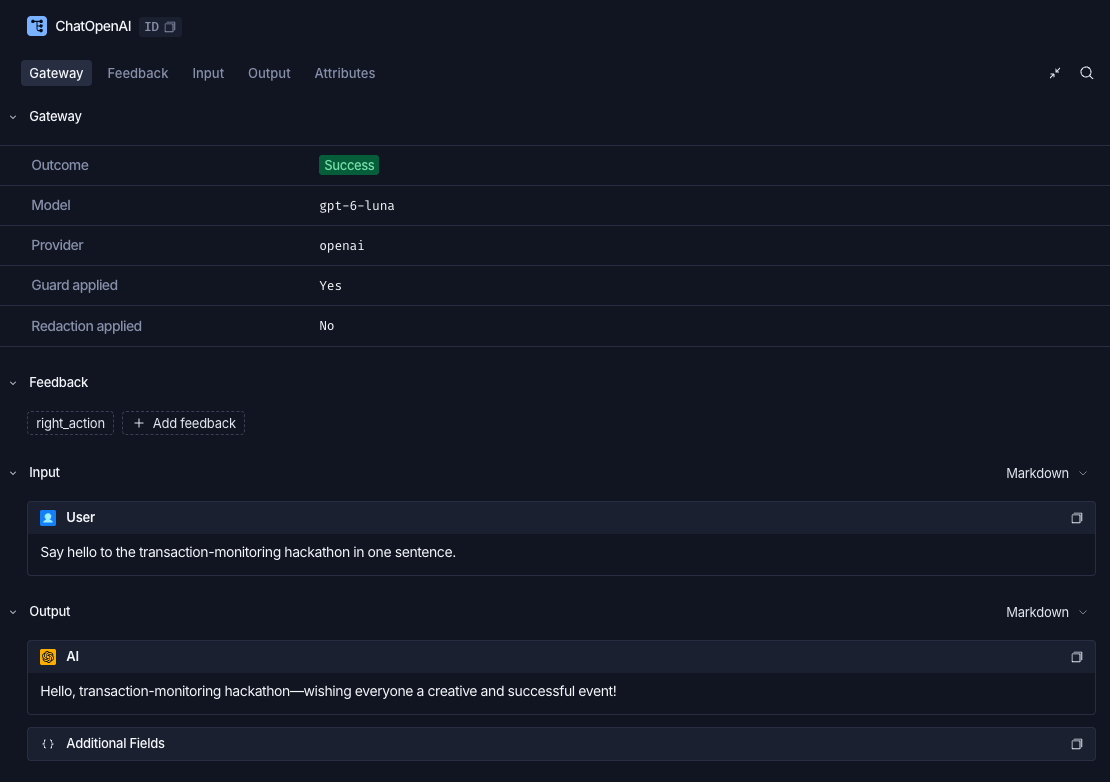

## Step 1: The bank's database (3 min)

The data lives in `data/` as **JSONL** files: one file per table, one JSON object per line, like rows in a
database table. `utils/db.py` reads them for us with three functions:

- `db.table("customer_profiles")`: every row in a table.
- `db.query("transactions", user_id="USR-001")`: the rows that match.
- `db.get("transactions", transaction_id="TX-1003")`: the first row that matches, or `None`.

| Table | What's in it |
|-------|--------------|
| `customer_profiles` | What the bank knows about each customer before any transactions arrive |
| `transactions` | Every card transaction |
| `reviewer_answers` | What a human reviewer says if the agent asks about a transaction |
| `analyst_labels` | Reference answers from analysts, for the evals in Module 2. The agent never sees them. |
| `simulated_annotations` | Reviews you can use in Module 3 if you're short on time |

We have two customers, each with a stream of card transactions:

| Customer | What happens in their stream |
|----------|------------------------------|
| `USR-001` Priya, London | Everyday spending, then a hotel in Lisbon (is she travelling?), dinner in Lisbon, then a crypto exchange and gift cards at 2am |
| `USR-002` Tomás, Lisbon | Everyday spending, then a coffee in Lisbon and, 25 minutes later, jewellery in Singapore |

In [ ]:
from utils import db

print(db.get("customer_profiles", user_id="USR-001"), "\n")
for tx in db.query("transactions", user_id="USR-001"):
    print(tx["transaction_id"], tx["timestamp"], tx["merchant"], tx["amount"], tx["currency"], tx["country"])

The table also holds transactions from 19 October, which you'll use in Module 3. Modules 1 and 2
use the data before. `transaction_stream` gives us one customer's transactions in the order they arrive.

In [ ]:
OCT_19 = "2026-10-19"  # Module 3's transactions start here

def transaction_stream(user_id: str, start: str | None = None, end: str | None = None) -> list[dict]:
    """A customer's transactions from the database, oldest first, from `start` up to (not including) `end`."""
    transactions = [
        tx
        for tx in db.query("transactions", user_id=user_id)
        if (start is None or tx["timestamp"] >= start) and (end is None or tx["timestamp"] < end)
    ]
    return sorted(transactions, key=lambda tx: tx["timestamp"])

if __name__ == "__main__":
    for user_id in ["USR-001", "USR-002"]:
        print(user_id, [tx["transaction_id"] for tx in transaction_stream(user_id, end=OCT_19)])    

## Step 2: Tools (6 min)

The agent's tools live in `tools/`, one file per area, and `agent.py` imports them. That's how the MDA project
structure organises them too. The agent gets three tools:

- `get_transaction` (`tools/transactions.py`) looks up a transaction in the database. The agent is only given
  the transaction's ID, so it fetches the details itself, as an analyst would.
- `get_customer_profile` (`tools/customers.py`) looks up what the bank knows about the customer, plus any notes
  human reviewers have left about them.
- `record_decision` (`tools/decisions.py`) records the agent's risk score, confidence and decision. **If the
  confidence is low, it pauses and asks a human.**

Every tool takes a `runtime` argument. LangChain fills it in for you and the model never sees it. It gives the
tool two things:

- `runtime.context`: information we pass in with each run. Here, the ID of the customer we're looking at, from
  `tools/context.py`. `get_transaction` only finds that customer's transactions, whatever ID the model asks for.
- `runtime.store`: the agent's **long-term memory**. We read and write it in *namespaces*, which work like
  folders, for example `("customer_notes", "USR-001")`.


### Don't rely on the model alone to know when it's unsure

The model reports a confidence with every score, but models are often more confident than they should be. So
before we trust that number, plain Python checks in `tools/decisions.py` look for cases a human should see
anyway:

- **Grey-zone score:** a score from 30 to 69 means "unusual, but could be legitimate". By the agent's own scoring
  guide, that's a case for a human.
- **Large payment abroad:** the agent wants to approve a payment in another country that's bigger than the
  customer usually spends.

If a check fires, the confidence is lowered to `CHECKED_CONFIDENCE`, below the threshold. The checks only ever
**lower** confidence, never raise it, so they can add human oversight but never remove it. Because they're
ordinary code, they're also easy to audit.

Try the checks on the hotel in Lisbon. With a grey-zone score, or a low score that would apply to a large
payment abroad, a human is asked to validate. With a clear fraud score the agent will block it anyway, so no check fires.

In [ ]:
from tools.decisions import confidence_checks

hotel = db.get("transactions", transaction_id="TX-1003")
for score in [50, 20, 90]:
    print(f"score {score}: {confidence_checks(score, hotel, 'USR-001')}")

Now `record_decision` is where the human comes in. `interrupt()` pauses the agent and hands a question to
whoever is running it. The agent waits until it's resumed with an answer, which becomes the return value of
`interrupt()`.

If the reviewer leaves a note, we save it to long-term memory so the agent can use it on future transactions.

When the LLM model processes the `record decision` tool, it cannot see `runtime` as an argument as that is passed silently. 

This allows data to be passed in your agent context without the model being aware and potentially leaking that to the end user.

In [ ]:
from tools.decisions import record_decision

for name, field in record_decision.tool_call_schema.model_json_schema()["properties"].items():
    print(f"{name}: {field.get('description')}")

## Step 3: Build the agent (4 min)

The system prompt lives in `instructions.md`. It tells the agent how to work through each
transaction and how to score. Open it to read it, or print it below.

We use `create_agent` to build the agent which automatically combines the model, tools and instructions. This creates a simple agent with a tool loop, that is executed until the task as defined in the instructions is completed.

In [ ]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent

from tools.customers import get_customer_profile
from tools.decisions import record_decision
from tools.transactions import get_transaction

from utils.models import PROJECT_ROOT, model
from utils.state import MyAgentContext


def build_agent(**kwargs):
    """Build a runnable agent with `create_agent`. Pass `checkpointer` and `store` to give it memory."""
    return create_agent(
        model=init_chat_model(model),
        tools=[get_customer_profile, get_transaction, record_decision],
        system_prompt=(PROJECT_ROOT / "instructions.md").read_text(),
        context_schema=MyAgentContext,
        **kwargs,
    )

This is the agent definition used in `create_agent`:

In [ ]:
print((PROJECT_ROOT / "instructions.md").read_text())

This is the loop `create_agent` built:

In [ ]:
try:
    from IPython.display import Image, display

    agent = build_agent()

    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception:
    print(agent.get_graph().draw_mermaid())

## Step 4: Add memory and send a transaction (5 min)

|   | Short-term memory | Long-term memory |
|---|-------------------|------------------|
| **Remembers** | This conversation: every transaction and decision so far | Facts about a customer, across all conversations |
| **Made with** | A *checkpointer*, plus a `thread_id` for each conversation | A *store*, organised into namespaces |
| **Here we use** | `InMemorySaver()` | `InMemoryStore()` |

The in-memory versions forget everything when the notebook restarts. In production you'd back them with a
database.

A helper `process_transactions` sends transactions to the agent one at a time on the same thread.
Each message holds only the transaction's ID; the agent looks up the rest. If the agent pauses for a human, it
answers from `reviewer_answers`. If there's no answer for that transaction, it accepts the agent's own decision.
You'll answer one yourself in step 6.

In [ ]:
from langgraph.types import Command

def process_transactions(agent, transactions: list[dict], thread_id: str, reviewer_answers: dict | None = None):
    """Send transactions to the agent one at a time, all on the same conversation thread."""
    config = {"configurable": {"thread_id": thread_id}}
    
    for tx in transactions:
        context = MyAgentContext(user_id=tx["user_id"])
        result = agent.invoke({"messages": [{"role": "user", "content": f"New transaction: {tx['transaction_id']}"}]}, config, context=context)

        while "__interrupt__" in result:
            question = result["__interrupt__"][0].value
            answer = (reviewer_answers or {}).get(question["transaction_id"], {"decision": question["agent_decision"]})
        
            print(f"  [human review requested for {question['transaction_id']}: {answer['decision']}]")
            result = agent.invoke(Command(resume=answer), config, context=context)
        
        print(f"{tx['transaction_id']}: {result['messages'][-1].text}")

Now an agent with memory, and Priya's first two transactions on her thread.

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore

# Add short term and long term memory
agent = build_agent(checkpointer=InMemorySaver(), store=InMemoryStore())

process_transactions(agent, transaction_stream("USR-001", end=OCT_19)[:2], thread_id="USR-001")

The checkpointer saved the whole conversation on the `USR-001` thread. Here it is: each transaction ID, the tool
calls the agent made to look it up and decide, and its replies.

In [ ]:
for message in agent.get_state({"configurable": {"thread_id": "USR-001"}}).values["messages"]:
    message.pretty_print()

## Step 5: Short-term memory in action (4 min)

Tomás buys a coffee in Lisbon, then 25 minutes later his card buys jewellery in Singapore. Nobody can travel
that fast. The agent can only spot this if it remembers the coffee, and that's what short-term memory is for.

In [ ]:
process_transactions(agent, transaction_stream("USR-002", end=OCT_19)[:4], thread_id="USR-002")

Now the same Singapore transaction on a **new thread**. A new `thread_id` is a new conversation, so the agent
has no memory of the coffee. Compare its answer with the one above.

In [ ]:
process_transactions(agent, transaction_stream("USR-002", end=OCT_19)[3:4], thread_id="USR-002-fresh")

## Step 6: Human in the loop (5 min)

Back to Priya. Her card pays a hotel in Lisbon, `TX-1003`. She lives in London and has never travelled before.
That's unusual, but people do go on holiday. Either the agent is unsure, or the confidence checks catch it, and
it pauses for you. The `why_review` field says which.

In [ ]:
import json

context = MyAgentContext(user_id="USR-001")
config = {"configurable": {"thread_id": context.user_id}}
transaction = db.get("transactions", transaction_id="TX-1003", user_id=context.user_id)

result = agent.invoke({"messages": [{"role": "user", "content": f"New transaction: {transaction}"}]}, config, context=context)
if "__interrupt__" in result:
    print("Paused for human review:")
    print(json.dumps(result["__interrupt__"][0].value, indent=2))
else:
    print("The agent was confident, so it didn't ask:", result["messages"][-1].text)

You're the reviewer. You called Priya, and she's on holiday. Approve the payment and leave a note, then resume
the agent with `Command(resume=...)`.

In [ ]:
reviewer_answer = {
    "decision": "approve",
    "note": "Customer confirmed by phone they are on holiday in Portugal from 3 to 5 October.",
}

if "__interrupt__" in result:
    result = agent.invoke(Command(resume=reviewer_answer), config, context=context)

print(result["messages"][-1].text)

## Step 7: Long-term memory in action (4 min)

Your note is now in the store, under Priya's namespace:

In [ ]:
for item in agent.store.search(("customer_notes", "USR-001")):
    print(item.key, item.value)

Next, Priya has dinner in Lisbon, `TX-1004`. We send it on a **new thread**, so the agent has no short-term
memory of the hotel. But `get_customer_profile` reads your note from long-term memory, so the agent knows she's
on holiday.

In [ ]:
dinner = db.get("transactions", transaction_id="TX-1004")

process_transactions(agent, [dinner], thread_id="USR-001-new-session")

## Step 8: Process whole streams (3 min)

Finally, a fresh agent with empty memory processes both customers' full streams. When it asks for help, the
answers come from the `reviewer_answers` table. Afterwards we read the audit log from the store. A `*` marks a
confidence that the checks lowered.

In [ ]:
def decision_log(store, user_id: str) -> list[dict]:
    """Every decision recorded for a customer, in transaction order."""
    items = store.search(("decisions", user_id), limit=1000)
    
    return sorted((item.value for item in items), key=lambda decision: decision["transaction_id"])

In [ ]:
agent = build_agent(checkpointer=InMemorySaver(), store=InMemoryStore())
reviewer_answers = {row["transaction_id"]: row for row in db.table("reviewer_answers")}

for customer in db.table("customer_profiles"):
    print(f"--- {customer['user_id']} ---")
    transactions = transaction_stream(customer["user_id"], end=OCT_19)
    process_transactions(agent, transactions, thread_id=customer["user_id"], reviewer_answers=reviewer_answers)

In [ ]:
for customer in db.table("customer_profiles"):
    for d in decision_log(agent.store, customer["user_id"]):
        lowered = "*" if d["confidence"] < d["model_confidence"] else " "
        print(
            f"{d['transaction_id']}  risk={d['risk_score']:>3}  confidence={d['confidence']:.2f}{lowered}  "
            f"{d['final_decision']:<7} decided by {d['decided_by']}"
        )

## Done! Where to look next

- **LangSmith:** if `LANGSMITH_TRACING=true` in `.env`, every run above is traced. Open your project to see each
  model call, tool call and interrupt.
- **LangGraph Studio:** run `uv run langgraph dev` in the `02_transaction_monitoring_agent` folder. Set the context to
  `{"user_id": "USR-001"}`, send `New transaction: TX-1003` as a message, and answer any review from the UI.
- **Managed Deep Agents:** run `uv run mda dev` to try the `agent` definition as a deep agent, and
  `uv run mda deploy` to deploy it. See the README.
- **Module 2:** measure how well the agent's scores line up with experienced analysts.

## Stretch goals

1. **Long streams.** Add `SummarizationMiddleware` so the conversation doesn't grow forever.
2. **More checks.** Add a deterministic check of your own to `confidence_checks`, such as a new merchant
   category or several payments within a few minutes.
3. **Let reviewers change the score.** Accept a corrected `risk_score` in the reviewer's answer and record it.
4. **Always check blocks.** Use `HumanInTheLoopMiddleware` to require approval before every block, whatever the
   confidence.
5. **Look up history.** Add a `get_recent_transactions` tool in `tools/transactions.py` that queries the
   customer's earlier transactions from the database. Does the Singapore jewellery in step 5 still slip through
   on a fresh thread?